# PP-LCNet textline_ori vs наша tiny CNN

**Что сравниваем** (без дообучения, всё «как есть»):

| модель | откуда | обучена на |
|---|---|---|
| `PP-LCNet_x0_25_textline_ori` | PaddleOCR, [ONNX с HF](https://hf.co/PaddlePaddle/PP-LCNet_x0_25_textline_ori_onnx), Apache-2.0 | внутренние данные PaddleOCR (документы, удостоверения; zh/en) |
| `PP-LCNet_x1_0_textline_ori` | [ONNX с HF](https://hf.co/PaddlePaddle/PP-LCNet_x1_0_textline_ori_onnx), Apache-2.0 | то же |
| `tiny CNN (ours)` | раздел 0 этого блокнота | только наша синтетика (20k рендеров, словарь без слов из теста) |

**Данные для оценки.** Всё внешнее, картинки из нашего теста не используются:
* **TextOCR `test`**: реальные кропы слов с фото, латиница. Ни одна модель на них не обучалась.
* **Bilingual RU-EN `val`**: синтетические кропы, кириллица и латиница.
* **RusTitW `test/real`** ([Kaggle](https://www.kaggle.com/datasets/hardtype/rustitw-russian-language-visual-text-recognition), Apache-2.0): **реальные фото с русским текстом**. Кропы нарезаны по размеченным рамкам абзацев, это главный набор для нашей задачи. RusTitW **полностью отложен**: ни препроцессинг, ни температура на нём не подбираются.

**Протокол.** Каждый кроп считаем upright (метка 0), его rot180 — перевёрнутым (метка 1). Каждый набор 50/50 по id картинки делим на `calib` и `eval`. На `calib` подбираем только препроцессинг и температуру, все метрики считаем на `eval`.

Главная метрика: **1 − Brier**. Также смотрим AUC, accuracy, ECE и logloss.

In [1]:
import os, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, onnxruntime as ort
from PIL import Image
from datasets import load_dataset
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
import json
import re
from pathlib import Path

import onnx
from huggingface_hub import hf_hub_download
ort.set_default_logger_severity(3)
plt.rcParams['figure.dpi'] = 90
N_PER_SET, SEED = 4000, 0
RUSTITW_TEST = Path('../data/rustitw/test/real')  # папка test/real из RusTitW: info.csv + images/
TINY_CNN = Path('tiny_cnn.pt')
LCNET_REPOS = {'PP-LCNet x0.25': 'PaddlePaddle/PP-LCNet_x0_25_textline_ori_onnx',
               'PP-LCNet x1.0': 'PaddlePaddle/PP-LCNet_x1_0_textline_ori_onnx'}
rng = np.random.default_rng(SEED)

textocr = load_dataset('MiXaiLL76/TextOCR_OCR', data_files={'test': 'data/test-00000-of-00001.parquet'},
                       split='test', verification_mode='no_checks').shuffle(seed=SEED).select(range(N_PER_SET))
biling = load_dataset('tehnik-tehnolog/bilingual-ocr-ru-en-synthetic', data_files={'val': 'data/val-00000-of-00001.parquet'},
                      split='val', verification_mode='no_checks').shuffle(seed=SEED).select(range(N_PER_SET))

def case_of(t):
    L = [c for c in t if c.isalpha()]
    if not L: return 'no_letters'
    if all(c.islower() for c in L): return 'lower'
    if all(c.isupper() for c in L): return 'upper' if len(L) > 1 else 'title'
    if L[0].isupper() and all(c.islower() for c in L[1:]): return 'title'
    return 'mixed'

def meta(ds, name):
    imgs = [r['image'].convert('RGB') for r in ds]
    m = pd.DataFrame({'text': ds['text'], 'w': [i.width for i in imgs], 'h': [i.height for i in imgs]})
    m['case'] = m.text.map(case_of); m['set'] = name
    m['split'] = np.where(rng.random(len(m)) < .5, 'calib', 'eval')
    return imgs, m

imgs_t, meta_t = meta(textocr, 'TextOCR')
imgs_b, meta_b = meta(biling, 'Bilingual')
meta_t['clean'] = (meta_t.w >= meta_t.h) & (meta_t.case != 'no_letters')    # без вертикальных и без «только цифры»
meta_b['clean'] = True
meta_b['script'] = biling['label']
print(meta_t.clean.mean(), 'доля clean в TextOCR')

# RusTitW test/real: кропы по размеченным рамкам (абзацы, могут быть многострочными)
info = pd.read_csv(RUSTITW_TEST / 'info.csv')
CYR, LAT = re.compile('[А-Яа-яЁё]'), re.compile('[A-Za-z]')
def script_of(t):
    c, l = bool(CYR.search(t)), bool(LAT.search(t))
    return 'mixed' if c and l else 'cyrillic' if c else 'latin' if l else 'no_letters'

imgs_r, rows, n_bad = [], [], 0
for _, r in info.iterrows():
    path = RUSTITW_TEST / 'images' / r.image_name
    im = Image.open(path).convert('RGB'); W, H = im.size
    for b in json.loads(r.box_and_label)[0]:
        if b.get('shape', 'rectangle') != 'rectangle' or 'label' not in b: continue
        if max(b['left'] + b['width'], b['top'] + b['height']) > 1.02: n_bad += 1; continue   # битые рамки не в долях
        x0, y0 = max(0, b['left'] * W), max(0, b['top'] * H)
        x1, y1 = min(W, x0 + b['width'] * W), min(H, y0 + b['height'] * H)
        x0, y0, x1, y1 = (int(round(v)) for v in (x0, y0, x1, y1))
        if x1 - x0 < 8 or y1 - y0 < 8: continue
        label = b['label'].replace('\\/n', '\n')
        imgs_r.append(im.crop((x0, y0, x1, y1)))
        rows.append({'text': label, 'w': x1 - x0, 'h': y1 - y0, 'photo': r.image_name, 'n_lines': label.count('\n') + 1})
meta_r = pd.DataFrame(rows)
meta_r['case'] = meta_r.text.map(case_of); meta_r['set'] = 'RusTitW'; meta_r['split'] = 'eval'
meta_r['script'] = meta_r.text.map(script_of)
meta_r['clean'] = (meta_r.w >= meta_r.h) & (meta_r.script != 'no_letters')
print(f"RusTitW: фото {meta_r.photo.nunique()}, кропов {len(meta_r)}, clean {meta_r.clean.mean():.2f}, отброшено битых рамок {n_bad}")
display(pd.crosstab(meta_r.script, meta_r.n_lines.clip(upper=3).map({1: '1 line', 2: '2 lines', 3: '3+ lines'})))

0.84375 доля clean в TextOCR


RusTitW: фото 363, кропов 926, clean 0.82, отброшено битых рамок 12


n_lines,1 line,2 lines,3+ lines
script,,,
cyrillic,291,173,126
latin,155,57,24
mixed,11,23,18
no_letters,43,2,3


## 0. Маленькая CNN на синтетике

Бейзлайн для сравнения: антисимметричная CNN на ~40k параметров, вход — серый кроп 32×128. Обучается только на собственной синтетике: слова из небольшого словаря (без слов из теста), отрисованные системными шрифтами macOS, с блюром, шумом, JPEG, окклюдерами и засветкой. Генератор работает только на macOS: шрифты берутся из `/System/Library/Fonts`.

In [ ]:
import io
import os
import random

import numpy as np
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFilter, ImageFont

SUP = '/System/Library/Fonts/Supplemental/'
FONTS = [SUP + f for f in ['Arial.ttf', 'Arial Bold.ttf', 'Arial Narrow.ttf', 'Arial Black.ttf', 'Georgia.ttf',
         'Georgia Bold.ttf', 'Times New Roman.ttf', 'Times New Roman Bold.ttf', 'Verdana.ttf', 'Verdana Bold.ttf',
         'Tahoma.ttf', 'Tahoma Bold.ttf', 'Trebuchet MS.ttf', 'Trebuchet MS Bold.ttf', 'Courier New.ttf',
         'Courier New Bold.ttf', 'Impact.ttf', 'Comic Sans MS.ttf', 'Arial Italic.ttf', 'PTSans.ttc', 'PTMono.ttc',
         'Microsoft Sans Serif.ttf', 'Baskerville.ttc']] + \
        ['/System/Library/Fonts/Helvetica.ttc', '/System/Library/Fonts/Avenir Next.ttc', '/System/Library/Fonts/HelveticaNeue.ttc',
         os.path.expanduser('~/Library/Fonts/YS Text-Bold.ttf'), os.path.expanduser('~/Library/Fonts/YS Text-Light.ttf'),
         os.path.expanduser('~/Library/Fonts/Inter-VariableFont_slnt,wght.ttf')]  # шрифты macOS

# Словарь составлен вручную из общеупотребительных слов; слов, увиденных на картинках теста, здесь нет.
WORDS_RU = '''продам куплю доставка ремонт квартира аренда магазин продукты аптека салон красоты шиномонтаж
автосервис запчасти открыто закрыто вход выход касса скидка акция распродажа новинка цена рублей телефон
улица проспект переулок дом подъезд этаж офис склад парковка кафе ресторан кофе хлеб молоко
овощи фрукты одежда обувь детский мир игрушки мебель кухни окна двери потолки ламинат плитка обои сантехника
электрика стройматериалы инструмент хозтовары цветы подарки ювелирный часы оптика стоматология клиника
медицинский центр банк банкомат почта связь интернет ноутбуки телефоны планшеты чехлы зарядка
наличные грузчики такси работа требуются вакансия зарплата график качество сервис бесплатно круглосуточно
понедельник пятница суббота воскресенье выходной обед часы работы продажа обмен кредит рассрочка
автомойка химчистка ателье парикмахерская маникюр фитнес бассейн школа курсы английский язык
здоровье общество ограниченной ответственностью индивидуальный предприниматель новый старый большой
маленький хороший город страна время человек день год рука работа слово место лицо друг глаз вопрос
дело сторона голова система жизнь книга сила вода отец мать история земля ребенок'''.split()
WORDS_EN = '''sale open closed coffee shop market service parts delivery pizza bar hotel store fresh
premium original quality free auto moto sport home style beauty studio express center group city new best
street road house world water people time year good great little right world night light power'''.split()


def rand_text():
    words = WORDS_RU if random.random() < 0.7 else WORDS_EN
    t = ' '.join(random.choice(words) for _ in range(random.choice([1, 1, 1, 2, 2, 3])))
    if random.random() < 0.12:
        t = random.choice([t + ' ' + str(random.randint(1, 999)), str(random.randint(10, 99999)),
                           '+7 ' + str(random.randint(900, 999)) + ' ' + str(random.randint(100, 999))])
    c = random.random()
    case = 'lower' if c < 0.35 else ('title' if c < 0.6 else 'upper')
    t = t.lower() if case == 'lower' else (t.capitalize() if case == 'title' else t.upper())
    if not any(ch.isalpha() for ch in t):
        case = 'digits'
    return t, case


def render(text):
    font = ImageFont.truetype(random.choice(FONTS), random.randint(28, 64))
    fg = np.random.randint(0, 256, 3); bg = np.random.randint(0, 256, 3)
    while np.abs(fg.astype(int) - bg).mean() < 60:
        bg = np.random.randint(0, 256, 3)
    l, t, r, b = font.getbbox(text)
    canvas = Image.new('RGB', (r - l + 40, b - t + 40), tuple(bg))
    ImageDraw.Draw(canvas).text((20 - l, 20 - t), text, font=font, fill=tuple(fg))
    if random.random() < 0.5:
        canvas = canvas.rotate(random.uniform(-4, 4), resample=Image.BILINEAR, fillcolor=tuple(bg))
    a = np.abs(np.asarray(canvas, np.float32) - bg).sum(-1) > 30
    ys, xs = np.where(a)
    if len(ys) == 0:
        return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    pad = lambda: int((y1 - y0) * random.uniform(0.0, 0.3))
    img = canvas.crop((max(0, x0 - pad()), max(0, y0 - pad()), x1 + pad(), y1 + pad()))
    th = random.randint(12, 60)
    img = img.resize((max(8, int(img.width * th / img.height)), th), Image.BILINEAR)
    if random.random() < 0.4:
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.2)))
    arr = np.asarray(img, np.float32) + np.random.normal(0, random.uniform(0, 12), (img.height, img.width, 3))
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    if random.random() < 0.6:
        buf = io.BytesIO(); img.save(buf, 'JPEG', quality=random.randint(25, 90)); img = Image.open(buf).convert('RGB')
    return img


def add_nuisance(img):
    a = np.asarray(img, np.float32).copy(); h, w = a.shape[:2]
    if random.random() < 0.5:
        yy, xx = np.mgrid[0:h, 0:w]
        cy = random.choice([0, h]) + random.uniform(-.3, .3) * h; cx = random.uniform(0, w)
        ry, rx = random.uniform(.4, 1.2) * h, random.uniform(.1, .5) * w
        a[((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 < 1] = np.random.randint(0, 256, 3) * random.uniform(.3, 1)
    if random.random() < 0.5:
        g = np.linspace(-1, 1, w)[None, :] * random.uniform(-80, 80) + np.linspace(-1, 1, h)[:, None] * random.uniform(-60, 60)
        a = a + g[..., None]
    return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))


def to_arr(img, H=32, W=128):
    x = np.asarray(img.convert('L').resize((W, H), Image.BILINEAR), np.float32) / 255.
    return (x - x.mean()) / (x.std() + 1e-3)


class OrientNet(nn.Module):
    """logit(x) = f(x) - f(rot180 x)  =>  p(rot x) = 1 - p(x) точно."""
    def __init__(self, c=(16, 32, 48)):
        super().__init__()
        layers, ci = [], 1
        for co in c:
            layers += [nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(), nn.MaxPool2d(2)]; ci = co
        self.f = nn.Sequential(*layers, nn.Conv2d(ci, ci, 3, padding=1), nn.ReLU(),
                               nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(ci, 1))

    def forward(self, x):
        return (self.f(x) - self.f(torch.flip(x, [2, 3]))).squeeze(1)


In [ ]:
TRAIN_TINY_CNN = True  # False: взять уже обученные веса из TINY_CNN
N_SYNTH, EPOCHS, BATCH = 20_000, 12, 256
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'

if TRAIN_TINY_CNN:
    random.seed(0)
    np.random.seed(0)
    torch.manual_seed(0)
    synth = []
    while len(synth) < N_SYNTH:
        im = render(rand_text()[0])
        if im is not None:
            synth.append(add_nuisance(im) if random.random() < 0.6 else im)
    X = torch.tensor(np.stack([to_arr(im) for im in synth]))[:, None]

    net = OrientNet().to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), 3e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3,
                                                total_steps=EPOCHS * (N_SYNTH // BATCH + 1))
    for epoch in range(EPOCHS):
        net.train()
        perm, total = torch.randperm(N_SYNTH), 0.0
        for i in range(0, N_SYNTH, BATCH):
            xb = X[perm[i:i + BATCH]]
            yb = (torch.rand(len(xb)) < 0.5).float()
            xb = torch.where(yb[:, None, None, None] > 0, torch.flip(xb, [2, 3]), xb)
            xb = xb * torch.where(torch.rand(len(xb), 1, 1, 1) < 0.5, -1.0, 1.0)  # полярность
            loss = nn.functional.binary_cross_entropy_with_logits(net(xb.to(DEVICE)),
                                                                  yb.to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            total += loss.item() * len(xb)
        print(f'epoch {epoch}: loss {total / N_SYNTH:.4f}')
    torch.save(net.cpu().state_dict(), TINY_CNN)

## 1. Модели и препроцессинг

Препроцессинг PP-LCNet берём из `inference.yml`: resize до 160×80 без сохранения пропорций, `/255`, нормализация ImageNet, CHW. Порядок каналов в yml явно не указан: PaddleX обычно читает картинки через OpenCV в BGR. Поэтому на **calib**-части TextOCR проверяем оба варианта и оставляем лучший.

In [2]:
MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)

def lcnet_prep(img, bgr):
    x = np.asarray(img.resize((160, 80), Image.BILINEAR), np.float32) / 255.
    if bgr: x = x[..., ::-1]
    return ((x - MEAN) / STD).transpose(2, 0, 1)

def make_sess(path, threads=None):
    so = ort.SessionOptions()
    if threads: so.intra_op_num_threads = threads
    return ort.InferenceSession(path, so, providers=['CPUExecutionProvider'])

LCNET = {name: hf_hub_download(repo, 'inference.onnx') for name, repo in LCNET_REPOS.items()}
sess = {k: make_sess(p) for k, p in LCNET.items()}

def lcnet_logit(name, imgs, bgr, bs=256):
    out = []
    for i in range(0, len(imgs), bs):
        x = np.stack([lcnet_prep(im, bgr) for im in imgs[i:i + bs]]).astype(np.float32)
        out.append(sess[name].run(None, {'x': x})[0])
    P = np.concatenate(out)
    return P, np.log(P[:, 1] + 1e-7) - np.log(P[:, 0] + 1e-7)     # logit P(180)

cnn = OrientNet(); cnn.load_state_dict(torch.load(TINY_CNN)); cnn.eval()
@torch.no_grad()
def cnn_logit(imgs, bs=512):
    X = torch.tensor(np.stack([to_arr(im) for im in imgs]))[:, None]
    return torch.cat([cnn(X[i:i + bs]) for i in range(0, len(X), bs)]).numpy()

# проверка: выход ONNX — уже softmax? и какой порядок каналов лучше (только calib)
cal = [im for im, s in zip(imgs_t, meta_t.split) if s == 'calib'][:1000]
cal_all = cal + [im.rotate(180) for im in cal]; y_cal = np.r_[np.zeros(len(cal)), np.ones(len(cal))]
rows = []
for name in LCNET:
    for bgr in [False, True]:
        P, z = lcnet_logit(name, cal_all, bgr)
        rows.append({'model': name, 'channels': 'BGR' if bgr else 'RGB', 'sum_probs≈1': np.allclose(P.sum(1), 1, atol=1e-3),
                     'acc': ((z > 0) == y_cal).mean(), 'AUC': roc_auc_score(y_cal, z)})
prep_df = pd.DataFrame(rows); display(prep_df.round(4))
BGR = {n: bool(prep_df[prep_df.model == n].sort_values('AUC').iloc[-1].channels == 'BGR') for n in LCNET}
print('выбранный порядок каналов:', BGR)

,model,channels,sum_probs≈1,acc,AUC
0,PP-LCNet x0.25,RGB,True,0.7275,0.8483
1,PP-LCNet x0.25,BGR,True,0.7285,0.8468
2,PP-LCNet x1.0,RGB,True,0.7080,0.8505
3,PP-LCNet x1.0,BGR,True,0.7060,0.8488


выбранный порядок каналов: {'PP-LCNet x0.25': False, 'PP-LCNet x1.0': False}


### Примеры кропов RusTitW

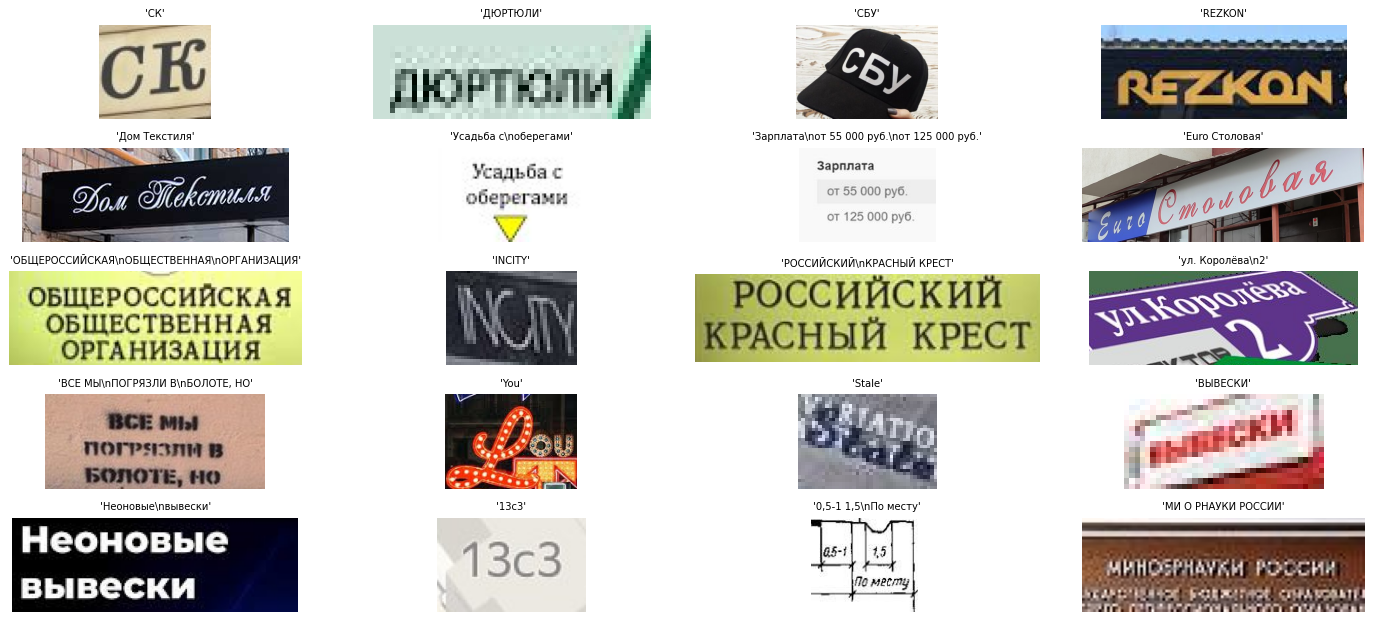

In [3]:
idx = rng.choice(np.where(meta_r.clean)[0], 20, replace=False)
fig, ax = plt.subplots(5, 4, figsize=(16, 7))
for a, i in zip(ax.ravel(), idx):
    a.imshow(imgs_r[i]); a.axis('off'); a.set_title(repr(meta_r.text[i][:40]), fontsize=8)
plt.tight_layout(); plt.show()

## 2. Предсказания в обеих ориентациях

In [4]:
def build(imgs, m):
    allimgs = imgs + [im.rotate(180) for im in imgs]
    df = pd.concat([m.assign(y=0), m.assign(y=1)], ignore_index=True)
    df['pair'] = np.r_[np.arange(len(imgs)), np.arange(len(imgs))]
    return allimgs, df

Z = {}
frames = []
SETS = [(imgs_t, meta_t), (imgs_b, meta_b), (imgs_r, meta_r)]
SIZES = [len(i) for i, _ in SETS]
for imgs, m in SETS:
    allimgs, df = build(imgs, m)
    for name in LCNET:
        df[name] = lcnet_logit(name, allimgs, BGR[name])[1]
    df['tiny CNN (ours)'] = cnn_logit(allimgs)
    frames.append(df)
D = pd.concat(frames, ignore_index=True)
MODELS = list(LCNET) + ['tiny CNN (ours)']

# антисимметричный TTA для PP-LCNet: z_sym(x) = (z(x) - z(rot x)) / 2  (x2 по времени)
for name in LCNET:
    z = D[name].values; zs = np.empty_like(z); off = 0
    for n in SIZES:
        a, b = z[off:off + n], z[off + n:off + 2 * n]
        zs[off:off + n], zs[off + n:off + 2 * n] = (a - b) / 2, (b - a) / 2; off += 2 * n
    D[name + ' +symTTA'] = zs
MODELS_ALL = MODELS + [n + ' +symTTA' for n in LCNET]

sig = lambda z: 1 / (1 + np.exp(-z))
for name in MODELS:
    p = sig(D[name].values); off = 0; cons = []
    for n in SIZES:
        cons.append(np.abs(p[off:off + n] + p[off + n:off + 2 * n] - 1).mean()); off += 2 * n
    print(f'{name:18s} consistency |p(x)+p(rot x)-1|: TextOCR {cons[0]:.3f}  Bilingual {cons[1]:.3f}  RusTitW {cons[2]:.3f}')

PP-LCNet x0.25     consistency |p(x)+p(rot x)-1|: TextOCR 0.442  Bilingual 0.053  RusTitW 0.439
PP-LCNet x1.0      consistency |p(x)+p(rot x)-1|: TextOCR 0.535  Bilingual 0.014  RusTitW 0.420
tiny CNN (ours)    consistency |p(x)+p(rot x)-1|: TextOCR 0.000  Bilingual 0.000  RusTitW 0.000


## 3. Метрики на `eval`: сырые вероятности и после temperature scaling

Temperature scaling: $p = \sigma(z/T)$, один параметр $T$ на модель, подбирается минимизацией Brier на `calib` (TextOCR-clean и Bilingual вместе, **без RusTitW**). Accuracy и AUC от этого не меняются, меняется только калибровка.

In [5]:
def ece(y, p, bins=15):
    conf = np.maximum(p, 1 - p); pred = (p > .5).astype(int); e = 0
    edges = np.linspace(.5, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        s = (conf > lo) & (conf <= hi)
        if s.any(): e += s.mean() * abs((pred[s] == y[s]).mean() - conf[s].mean())
    return e

def metrics(y, z, T=1.0):
    p = np.clip(sig(z / T), 1e-6, 1 - 1e-6)
    return {'1-Brier': 1 - brier_score_loss(y, p), 'AUC': roc_auc_score(y, z), 'acc': ((z > 0) == y).mean(),
            'ECE': ece(y, p), 'logloss': log_loss(y, p)}

calib_mask = (D.split == 'calib') & D.clean
TEMP = {}
for name in MODELS_ALL:
    y, z = D.y[calib_mask].values, D[name][calib_mask].values
    TEMP[name] = minimize_scalar(lambda T: brier_score_loss(y, sig(z / T)), bounds=(0.05, 50), method='bounded').x

rows = []
for (setname, sub) in [('TextOCR clean', (D.set == 'TextOCR') & D.clean), ('TextOCR all', D.set == 'TextOCR'),
                        ('Bilingual', D.set == 'Bilingual'),
                        ('RusTitW clean', (D.set == 'RusTitW') & D.clean),
                        ('RusTitW cyr', (D.set == 'RusTitW') & D.clean & (D.script == 'cyrillic')),
                        ('RusTitW cyr 1-line', (D.set == 'RusTitW') & D.clean & (D.script == 'cyrillic') & (D.n_lines == 1)),
                        ('RusTitW lat', (D.set == 'RusTitW') & D.clean & (D.script == 'latin'))]:
    s = sub & (D.split == 'eval')
    for name in MODELS_ALL:
        for mode, T in [('raw', 1.0), ('T-scaled', TEMP[name])]:
            rows.append({'set': setname, 'model': name, 'probs': mode, 'n': int(s.sum()), 'T': T, **metrics(D.y[s].values, D[name][s].values, T)})
R = pd.DataFrame(rows)
print('температуры:', {k: round(v, 2) for k, v in TEMP.items()})
display(R.pivot_table(index=['model', 'probs'], columns='set', values='1-Brier').round(4))
display(R[R.probs == 'T-scaled'].pivot_table(index='model', columns='set', values=['AUC', 'acc', 'ECE']).round(4))

температуры: {'PP-LCNet x0.25': np.float64(2.15), 'PP-LCNet x1.0': np.float64(3.31), 'tiny CNN (ours)': np.float64(2.02), 'PP-LCNet x0.25 +symTTA': np.float64(0.82), 'PP-LCNet x1.0 +symTTA': np.float64(0.92)}


set                              Bilingual  RusTitW clean  RusTitW cyr  \
model                  probs                                             
PP-LCNet x0.25         T-scaled     0.9689         0.7717       0.7671   
                       raw          0.9770         0.7295       0.7222   
PP-LCNet x0.25 +symTTA T-scaled     0.9840         0.7971       0.7841   
                       raw          0.9835         0.8047       0.7930   
PP-LCNet x1.0          T-scaled     0.9857         0.8246       0.8272   
                       raw          0.9927         0.7896       0.7948   
PP-LCNet x1.0 +symTTA  T-scaled     0.9941         0.8739       0.8733   
                       raw          0.9941         0.8754       0.8748   
tiny CNN (ours)        T-scaled     0.9204         0.7289       0.7494   
                       raw          0.9193         0.6817       0.7071   

set                              RusTitW cyr 1-line  RusTitW lat  TextOCR all  \
model                  probs                                                    
PP-LCNet x0.25         T-scaled              0.8187       0.7835       0.8181   
                       raw                   0.7888       0.7491       0.7883   
PP-LCNet x0.25 +symTTA T-scaled              0.8538       0.8275       0.8980   
                       raw                   0.8593       0.8330       0.8993   
PP-LCNet x1.0          T-scaled              0.8657       0.8245       0.8150   
                       raw                   0.8491       0.7881       0.7617   
PP-LCNet x1.0 +symTTA  T-scaled              0.9207       0.8817       0.9299   
                       raw                   0.9218       0.8835       0.9304   
tiny CNN (ours)        T-scaled              0.8097       0.6736       0.7937   
                       raw                   0.7858       0.6100       0.7635   

set                              TextOCR clean  
model                  probs                    
PP-LCNet x0.25         T-scaled         0.8372  
                       raw              0.8123  
PP-LCNet x0.25 +symTTA T-scaled         0.9206  
                       raw              0.9206  
PP-LCNet x1.0          T-scaled         0.8304  
                       raw              0.7845  
PP-LCNet x1.0 +symTTA  T-scaled         0.9510  
                       raw              0.9511  
tiny CNN (ours)        T-scaled         0.8081  
                       raw              0.7820

AUC                                               \
set                    Bilingual RusTitW clean RusTitW cyr RusTitW cyr 1-line   
model                                                                           
PP-LCNet x0.25            0.9965        0.7187      0.7120             0.8160   
PP-LCNet x0.25 +symTTA    0.9982        0.7945      0.7774             0.8895   
PP-LCNet x1.0             0.9997        0.8245      0.8277             0.8986   
PP-LCNet x1.0 +symTTA     0.9998        0.9109      0.9094             0.9659   
tiny CNN (ours)           0.9600        0.6305      0.6682             0.7951   

                                                                   ECE  \
set                    RusTitW lat TextOCR all TextOCR clean Bilingual   
model                                                                    
PP-LCNet x0.25              0.7452      0.8515        0.8797    0.0664   
PP-LCNet x0.25 +symTTA      0.8402      0.9386        0.9613    0.0100   
PP-LCNet x1.0               0.8316      0.8562        0.8812    0.0653   
PP-LCNet x1.0 +symTTA       0.9265      0.9689        0.9829    0.0044   
tiny CNN (ours)             0.5283      0.7556        0.7891    0.0307   

                                                  ...                          \
set                    RusTitW clean RusTitW cyr  ... RusTitW lat TextOCR all   
model                                             ...                           
PP-LCNet x0.25                0.1257      0.1348  ...      0.1099      0.0924   
PP-LCNet x0.25 +symTTA        0.1413      0.1646  ...      0.1415      0.0313   
PP-LCNet x1.0                 0.0360      0.0411  ...      0.0634      0.0825   
PP-LCNet x1.0 +symTTA         0.0664      0.0683  ...      0.0765      0.0244   
tiny CNN (ours)               0.1805      0.1570  ...      0.2767      0.0869   

                                           acc                            \
set                    TextOCR clean Bilingual RusTitW clean RusTitW cyr   
model                                                                      
PP-LCNet x0.25                0.0727    0.9683        0.6393      0.6345   
PP-LCNet x0.25 +symTTA        0.0196    0.9792        0.7135      0.6951   
PP-LCNet x1.0                 0.0679    0.9896        0.7431      0.7566   
PP-LCNet x1.0 +symTTA         0.0153    0.9921        0.8200      0.8220   
tiny CNN (ours)               0.0750    0.8912        0.5756      0.5966   

                                                                   \
set                    RusTitW cyr 1-line RusTitW lat TextOCR all   
model                                                               
PP-LCNet x0.25                     0.7242      0.6612      0.7334   
PP-LCNet x0.25 +symTTA             0.7817      0.7596      0.8497   
PP-LCNet x1.0                      0.8194      0.7322      0.7143   
PP-LCNet x1.0 +symTTA              0.8929      0.8306      0.8933   
tiny CNN (ours)                    0.7103      0.5082      0.6704   

                                      
set                    TextOCR clean  
model                                 
PP-LCNet x0.25                0.7610  
PP-LCNet x0.25 +symTTA        0.8885  
PP-LCNet x1.0                 0.7390  
PP-LCNet x1.0 +symTTA         0.9283  
tiny CNN (ours)               0.7040  

[5 rows x 21 columns]

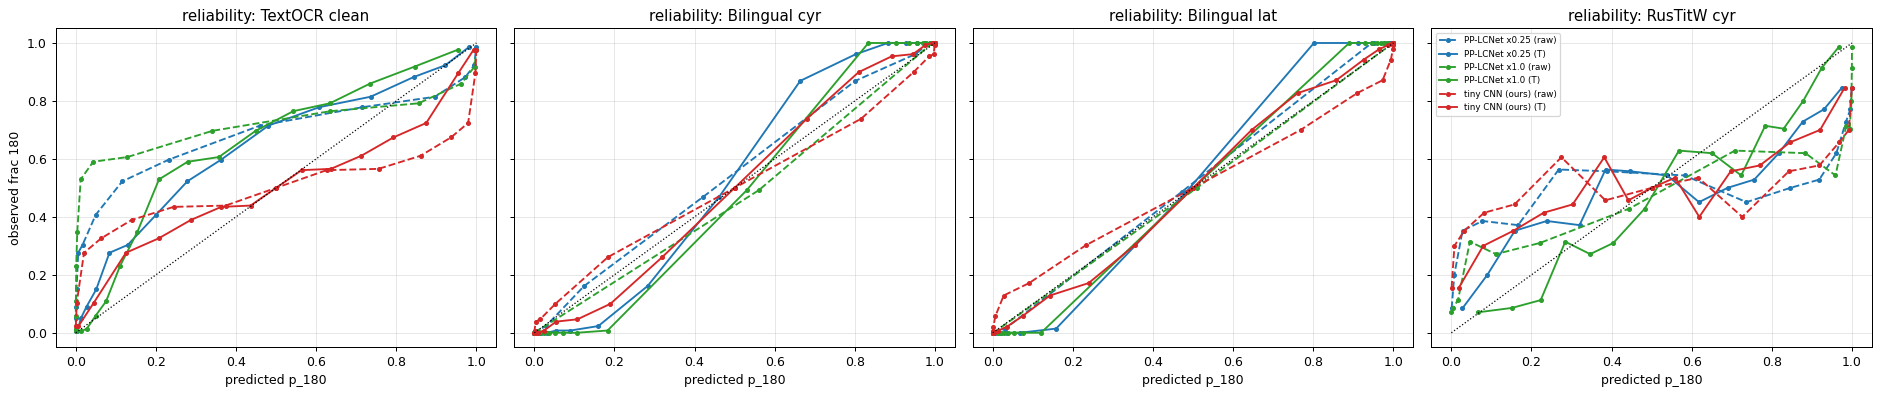

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5), sharey=True)
for a, (setname, sub) in zip(ax, [('TextOCR clean', (D.set == 'TextOCR') & D.clean), ('Bilingual cyr', (D.set == 'Bilingual') & (D.script == 'cyrillic')),
                                 ('Bilingual lat', (D.set == 'Bilingual') & (D.script == 'latin')),
                                 ('RusTitW cyr', (D.set == 'RusTitW') & D.clean & (D.script == 'cyrillic'))]):
    s = sub & (D.split == 'eval')
    for name in MODELS:
        for mode, T, ls in [('raw', 1.0, '--'), ('T', TEMP[name], '-')]:
            p = sig(D[name][s].values / T); y = D.y[s].values
            q = pd.qcut(p, 15, labels=False, duplicates='drop')
            a.plot(pd.Series(p).groupby(q).mean(), pd.Series(y).groupby(q).mean(), ls, marker='o', ms=3,
                   label=f'{name} ({mode})', color={'PP-LCNet x0.25': 'tab:blue', 'PP-LCNet x1.0': 'tab:green', 'tiny CNN (ours)': 'tab:red'}[name])
    a.plot([0, 1], [0, 1], 'k:', lw=1); a.set_title(f'reliability: {setname}'); a.set_xlabel('predicted p_180'); a.grid(alpha=.3)
ax[0].set_ylabel('observed frac 180'); ax[-1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Откуда берётся consistency ≈ 0.5 у PP-LCNet на TextOCR

Если модель уверенно говорит «0°» и для картинки, и для её поворота, то $p(x)+p(\mathrm{rot}\,x)\approx 0$. Смотрим точность отдельно по истинному классу: сильный перекос означает, что на незнакомом домене модель по умолчанию отвечает «0°».

In [7]:
s = (D.split == 'eval') & (D.set == 'TextOCR') & D.clean
rows = []
for name in MODELS_ALL:
    z = D[name][s].values; y = D.y[s].values
    rows.append({'model': name, 'acc | y=0 (upright)': ((z > 0) == y)[y == 0].mean(), 'acc | y=1 (rot180)': ((z > 0) == y)[y == 1].mean(),
                 'mean p_180': sig(z).mean()})
display(pd.DataFrame(rows).set_index('model').round(3))

,acc | y=0 (upright),acc | y=1 (rot180),mean p_180
model,,,
PP-LCNet x0.25,0.905,0.617,0.364
PP-LCNet x1.0,0.908,0.570,0.332
tiny CNN (ours),0.704,0.704,0.500
PP-LCNet x0.25 +symTTA,0.888,0.888,0.500
PP-LCNet x1.0 +symTTA,0.928,0.928,0.500


## 4. Разрезы (после temperature scaling, `eval`)

In [8]:
E = D[D.split == 'eval'].copy()
for name in MODELS:
    p = sig(E[name] / TEMP[name]); E[name + ' _sq'] = (p - E.y) ** 2
sq = [n + ' _sq' for n in MODELS]
ren = lambda t: (1 - t).rename(columns=lambda c: c.replace(' _sq', '')).round(3)

E['h_bin'] = pd.cut(E.h, [0, 40, 60, 100, 10000], labels=['<40', '40-60', '60-100', '>100'])
t = E[E.set == 'TextOCR']
print('TextOCR, 1-Brier по группам')
display(ren(t.groupby('case')[sq].mean()).assign(n=t.groupby('case').size()))
display(ren(t.groupby(t.w >= t.h)[sq].mean()).rename_axis('w >= h').assign(n=t.groupby(t.w >= t.h).size()))
display(ren(t[t.clean].groupby('h_bin')[sq].mean()).rename_axis('h (clean)'))
b = E[E.set == 'Bilingual']
print('Bilingual, 1-Brier по группам')
display(ren(b.groupby(['script', 'case'])[sq].mean()).assign(n=b.groupby(['script', 'case']).size()))
r = E[(E.set == 'RusTitW')].copy(); r['lines'] = r.n_lines.clip(upper=3).map({1: '1', 2: '2', 3: '3+'})
print('RusTitW, 1-Brier по группам')
display(ren(r.groupby(['script', 'lines'])[sq].mean()).assign(n=r.groupby(['script', 'lines']).size()))
rc = r[r.clean & (r.script == 'cyrillic')]
display(ren(rc.groupby('case')[sq].mean()).rename_axis('RusTitW cyr: case').assign(n=rc.groupby('case').size()))
display(ren(rc.groupby('h_bin')[sq].mean()).rename_axis('RusTitW cyr: h').assign(n=rc.groupby('h_bin').size()))
display(ren(r.groupby(r.w >= r.h)[sq].mean()).rename_axis('RusTitW: w >= h').assign(n=r.groupby(r.w >= r.h).size()))

TextOCR, 1-Brier по группам


,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours),n
case,,,,
lower,0.810,0.804,0.784,772
mixed,0.860,0.867,0.800,138
no_letters,0.739,0.748,0.727,352
title,0.816,0.818,0.770,898
upper,0.835,0.828,0.823,1778


,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours),n
w >= h,,,,
False,0.683,0.706,0.711,360
True,0.832,0.826,0.802,3578


/var/folders/w3/4nl0r9vd1xl15fkg3mfm2ps80000gn/T/ipykernel_51741/3479262016.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(ren(t[t.clean].groupby('h_bin')[sq].mean()).rename_axis('h (clean)'))


,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours)
h (clean),,,
<40,0.868,0.829,0.840
40-60,0.836,0.822,0.810
60-100,0.810,0.829,0.786
>100,0.833,0.861,0.778


Bilingual, 1-Brier по группам


... (3 outputs left out)

,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours),n
RusTitW cyr: case,,,,
lower,0.763,0.820,0.760,266
mixed,0.748,0.826,0.706,204
title,0.785,0.817,0.751,172
upper,0.772,0.837,0.763,414


/var/folders/w3/4nl0r9vd1xl15fkg3mfm2ps80000gn/T/ipykernel_51741/3479262016.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(ren(rc.groupby('h_bin')[sq].mean()).rename_axis('RusTitW cyr: h').assign(n=rc.groupby('h_bin').size()))
/var/folders/w3/4nl0r9vd1xl15fkg3mfm2ps80000gn/T/ipykernel_51741/3479262016.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(ren(rc.groupby('h_bin')[sq].mean()).rename_axis('RusTitW cyr: h').assign(n=rc.groupby('h_bin').size()))


,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours),n
RusTitW cyr: h,,,,
<40,0.788,0.853,0.804,296
40-60,0.783,0.819,0.785,216
60-100,0.743,0.808,0.702,214
>100,0.753,0.822,0.708,330


,PP-LCNet x0.25,PP-LCNet x1.0,tiny CNN (ours),n
RusTitW: w >= h,,,,
False,0.716,0.746,0.705,264
True,0.775,0.826,0.730,1588


## 5. Скорость и размер

CPU (Apple Silicon). Замер в двух режимах: 1 поток и batch=1 (латентность), затем все потоки и batch=256 (пропускная способность). Препроцессинг не входит.

In [9]:
def n_params_onnx(path):
    return sum(int(np.prod(t.dims)) for t in onnx.load(path).graph.initializer)

sample = imgs_t[:512]
Xl = {n: np.stack([lcnet_prep(im, BGR[n]) for im in sample]).astype(np.float32) for n in LCNET}
Xc = torch.tensor(np.stack([to_arr(im) for im in sample]))[:, None]

def bench(fn, X, bs, reps=3):
    fn(X[:bs]); best = 1e9
    for _ in range(reps):
        t0 = time.perf_counter()
        for i in range(0, len(X), bs): fn(X[i:i + bs])
        best = min(best, time.perf_counter() - t0)
    return best / len(X) * 1e3

rows = []
for n, p in LCNET.items():
    s1, sN = make_sess(p, threads=1), make_sess(p)
    npar = n_params_onnx(p)
    rows.append({'model': n, 'input': '3×80×160', 'params': npar, 'file MB': os.path.getsize(p) / 1e6,
                 'ms/img 1thr bs1': bench(lambda x: s1.run(None, {'x': x}), Xl[n][:128], 1),
                 'ms/img all bs256': bench(lambda x: sN.run(None, {'x': x}), Xl[n], 256)})
torch.set_num_threads(1)
with torch.no_grad():
    lat = bench(lambda x: cnn(x), Xc[:128], 1)
torch.set_num_threads(os.cpu_count())
with torch.no_grad():
    thr = bench(lambda x: cnn(x), Xc, 256)
rows.append({'model': 'tiny CNN (ours)', 'input': '1×32×128', 'params': sum(p.numel() for p in cnn.parameters()),
             'file MB': os.path.getsize(TINY_CNN) / 1e6, 'ms/img 1thr bs1': lat, 'ms/img all bs256': thr})
display(pd.DataFrame(rows).set_index('model').round(3))
print('Замечание: tiny CNN из-за антисимметричной головы делает 2 прохода (x и rot x), это уже учтено в замере.')

,input,params,file MB,ms/img 1thr bs1,ms/img all bs256
model,,,,,
PP-LCNet x0.25,3×80×160,NaN,1.019,1.136,0.485
PP-LCNet x1.0,3×80×160,NaN,6.778,7.673,2.860
tiny CNN (ours),1×32×128,39601.0,0.167,0.770,0.301


Замечание: tiny CNN из-за антисимметричной головы делает 2 прохода (x и rot x), это уже учтено в замере.


## 6. Уверенные ошибки (eval, clean)

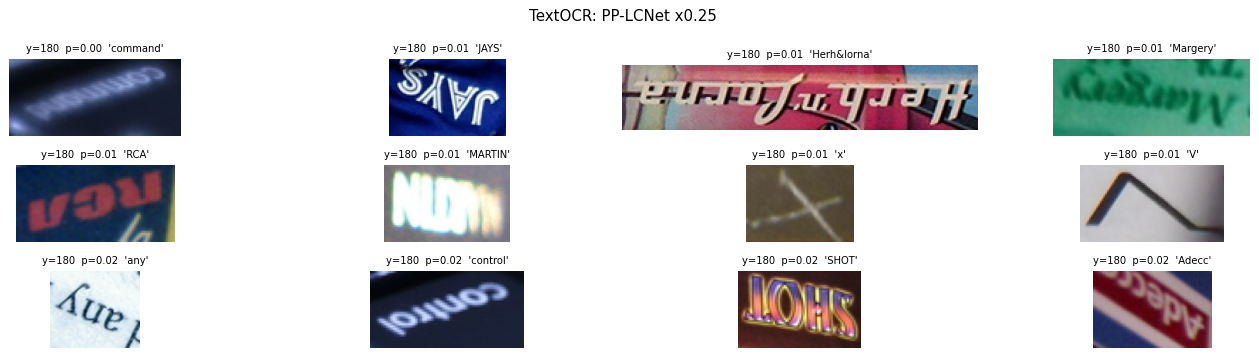

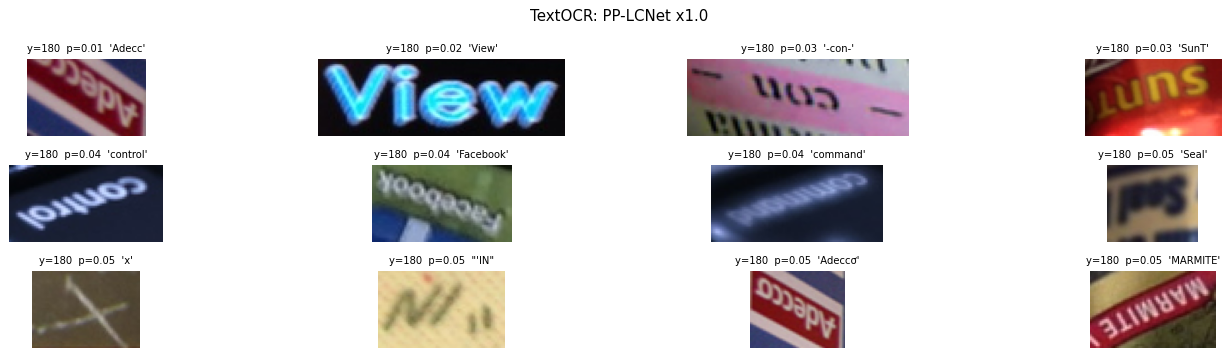

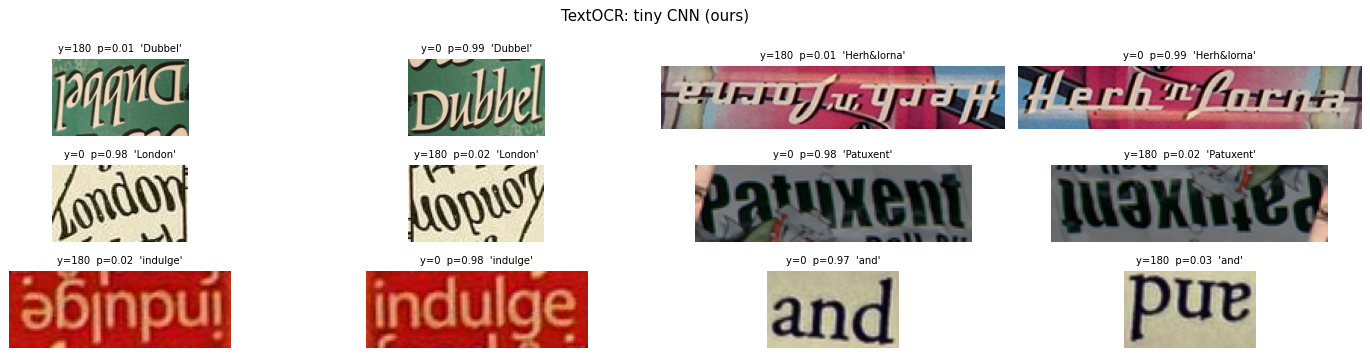

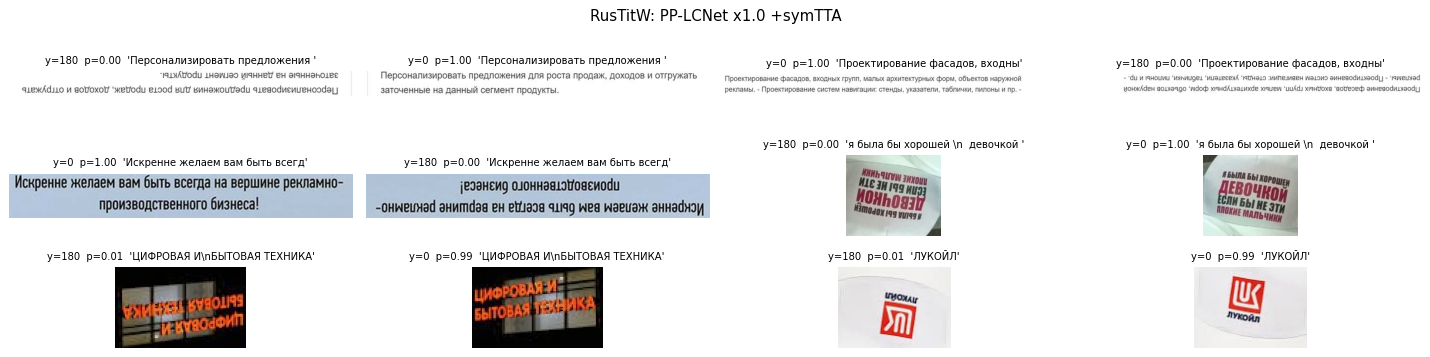

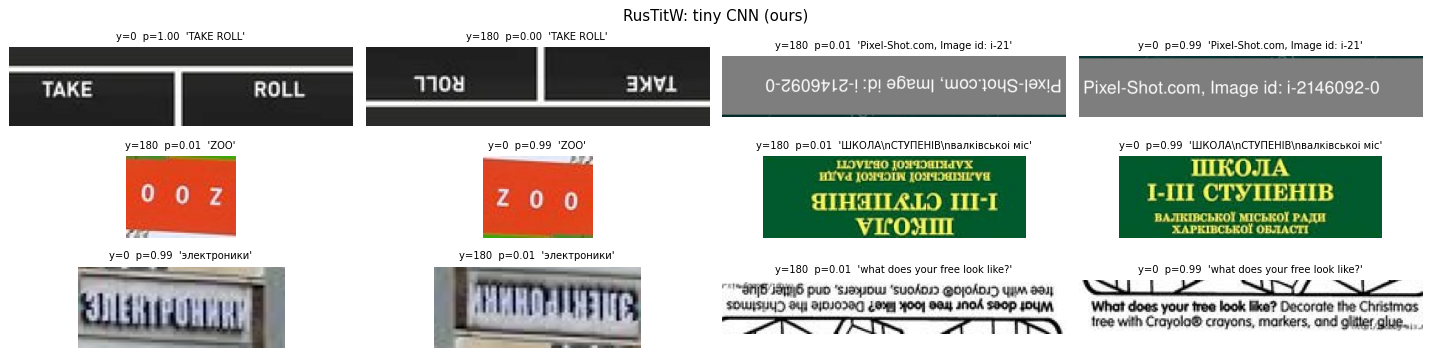

In [10]:
SRC = {'TextOCR': imgs_t, 'RusTitW': imgs_r}
def show_errors(name, setname='TextOCR', k=12):
    s = E[(E.set == setname) & E.clean].copy()
    s['p'] = sig(s[name] / TEMP[name]); s['err'] = np.abs(s.p - s.y)
    top = s.sort_values('err', ascending=False).head(k)
    fig, ax = plt.subplots(k // 4, 4, figsize=(16, 1.4 * k // 4))
    for a, (_, r) in zip(ax.ravel(), top.iterrows()):
        im = SRC[setname][int(r.pair)]; im = im.rotate(180) if r.y == 1 else im
        a.imshow(im); a.axis('off'); a.set_title(f"y={'180' if r.y else '0'}  p={r.p:.2f}  {r.text[:30]!r}", fontsize=8)
    fig.suptitle(f'{setname}: {name}'); plt.tight_layout(); plt.show()

for name in MODELS: show_errors(name, 'TextOCR')
for name in ['PP-LCNet x1.0 +symTTA', 'tiny CNN (ours)']: show_errors(name, 'RusTitW')

## 7. Выводы

> RusTitW пока **частичный**: 363 фото из 3 795, 926 кропов, из них ~590 чистых кириллических. Kaggle ограничивает частоту скачивания (429), остальное докачивается. Доверительные интервалы по RusTitW широкие, примерно ±0.02–0.03.

**1 − Brier** (T подобран на calib TextOCR+Bilingual; RusTitW полностью отложен):

| модель | TextOCR clean (реальн., лат.) | Bilingual (синт.) | **RusTitW cyr** (реальн.) | **RusTitW cyr, 1 строка** | RusTitW lat | размер | ms/img |
|---|---|---|---|---|---|---|---|
| tiny CNN (ours) | 0.808 | 0.920 | 0.749 | 0.810 | 0.674 | 0.17 MB | 0.77 |
| PP-LCNet x0.25 | 0.837 | 0.969 | 0.767 | 0.819 | 0.784 | 1.0 MB | 1.1 |
| PP-LCNet x1.0 | 0.830 | 0.986 | 0.827 | 0.866 | 0.825 | 6.8 MB | 7.7 |
| PP-LCNet x0.25 + symTTA | 0.921 | 0.984 | 0.784 | 0.854 | 0.828 | 1.0 MB | ~2.3 |
| **PP-LCNet x1.0 + symTTA** | **0.951** | **0.994** | **0.873** | **0.921** | **0.882** | 6.8 MB | ~15 |

1. **Синтетика сильно завышает оценку.** На кириллице Bilingual даёт 0.98–0.99, а реальная кириллица RusTitW — 0.87 (все кропы) и 0.92 (однострочные) у лучшей модели. Проверка на реальной кириллице была нужна.
2. **Многострочные кропы — главная слабость PP-LCNet.** Модель обучена на отдельных строках: 1 строка 0.85, 2 строки 0.79, 3+ строки 0.79 (x1.0, кириллица). Её уверенные ошибки на RusTitW — в основном абзацы из 2–3 строк и мелкий «документный» текст. В нашем тесте кропы в основном однострочные, поэтому ближе всего к тесту колонка «cyr, 1 строка».
3. **Смещение к 0° повторяется и на реальной кириллице:** consistency ≈ 0.42–0.44. Симметризация снова даёт основной прирост: x1.0 0.827 → 0.873, x0.25 0.767 → 0.784.
4. **Ширина модели важнее на реальной кириллице:** x1.0 заметно лучше x0.25 (0.873 против 0.784). На TextOCR разрыв меньше (0.951 против 0.921).
5. **Наша tiny CNN** на реальных данных худшая (0.75 кир., 0.67 лат.). Синтетики из 20k рендеров для реальных фото мало.
6. **Уверенные ошибки на RusTitW** — это многострочный текст, мелкий текст на белом фоне и логотипы (ЛУКОЙЛ). Часть из них, вероятно, шум разметки: сам исходный кроп перевёрнут.

**Для решения:** стартовая точка — PP-LCNet x1.0 + symTTA, около 0.92 на реальной однострочной кириллице. Главные направления улучшений:
- дообучить на реальной кириллице (RusTitW train, 10k фото) и латинице (TextOCR train), включая многострочные кропы, с антисимметричной головой;
- для скорости — дистиллировать x1.0 в x0.25 или в свою маленькую CNN.